# NEP panel: delay and cancellation per phase

Data: `data/pypsa-de/grid_delay/nep_panel/` in this repository, a copy of the `nep_panel` outputs (v0.13.0, 2026-11-04):
`panel.csv` (one row per line and report) and `lines.csv` (one row per line). Definitions: `nep_panel/docs/data.md`.

1. Tables 1-2 and Figures 0-2 recompute `delay_table.csv` and `cancellation.csv` independently; a check cell
   compares them.
2. The second part (from "Inputs for the probability builder") estimates what
   `build_probabilities_from_nep_panel.ipynb` needs and writes it to the same folder:
   `delay_pmf.csv`, `cancel_rate.csv`, `delay_correlation.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, rankdata

DATA = Path.cwd().parent / "data" / "pypsa-de" / "grid_delay" / "nep_panel"
LADDER = ["under_consideration", "confirmed", "in_permitting", "under_construction", "commissioned"]
OPEN = LADDER[:-1]
EXACT = ["day", "month", "quarter", "year", "report_stage5", "sections"]
CENSOR_YEAR = 2026
COLOURS = dict(zip(OPEN, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

MIN_KM = 0  # Table 2 sample: 0 = all lines, 20 = lines > 20 km

In [2]:
panel = pd.read_csv(DATA / "panel.csv")
lines = pd.read_csv(DATA / "lines.csv")
keep = (lines.kind != "substation") & (lines.purpose != "wind_connection")
units = panel[panel.line_id.isin(lines.line_id[keep])]  # no substations, no wind connections
lines.outcome.value_counts()

outcome
planned         649
cancelled       509
commissioned    202
unknown         151
replaced         33
Name: count, dtype: int64

In [3]:
def decimal(t: pd.Series) -> pd.Series:
    """Timestamps as decimal years."""
    return t.dt.year + (t.dt.day_of_year - 1) / 365.25


def actual_time(df: pd.DataFrame) -> pd.Series:
    """Commissioning time in decimal years; year-only dates sit at mid-year."""
    d = df.actual_date.fillna("").astype(str)
    d = d.str.replace(r"^(\d{4})-Q(\d)$", lambda m: f"{m[1]}-{3 * int(m[2]) - 1:02d}-15", regex=True)
    d = d.str.replace(r"^(\d{4}-\d{2})$", r"\1-15", regex=True)
    t = decimal(pd.to_datetime(d.where(d.str.match(r"^\d{4}-\d{2}-\d{2}$")), errors="coerce"))
    return t.fillna(df.actual_year + 0.5)


# first report of each line in each open phase, with its outcome
obs = units[units.status.isin(OPEN)].sort_values("ref_date").drop_duplicates(["line_id", "status"])
cols = ["line_id", "outcome", "precision", "actual_year", "last_target"]
obs = obs.merge(lines[cols].assign(exact=lines.precision.isin(EXACT)), on="line_id")
obs["delay"] = obs.actual_year - obs.target_hi
so_far = obs.last_target.clip(lower=CENSOR_YEAR) - obs.target_hi
follow_up = obs.ref_date < panel.ref_date.max()  # D20: entries in the latest report give no bound
obs["delay_lb"] = obs.delay.where(obs.exact, so_far.where((obs.outcome == "planned") & follow_up))

# time from first report in a phase to first report in any later phase (commissioning = actual time)
first = panel[panel.status.isin(OPEN)].assign(t=lambda d: decimal(pd.to_datetime(d.ref_date)))
first = first.groupby(["line_id", "status"]).t.min().reset_index()
done = lines[lines.precision.isin(EXACT)].assign(status="commissioned", t=actual_time)
first = pd.concat([first, done[["line_id", "status", "t"]]])
first["rank"] = first.status.map(LADDER.index)
first = first.sort_values(["line_id", "rank"])
nxt = first.groupby("line_id")[["status", "t"]].shift(-1)
durations = first.assign(next_status=nxt.status, years=nxt.t - first.t).dropna(subset=["next_status"])
durations = durations[durations.years >= 0]

**Figure 0.** Lines per phase pair: number of lines reported in the start phase that later reached
the end phase or beyond (commissioned = outcome commissioned). Each cell is the sample behind a
phase-to-phase statistic; no substations, any outcome.

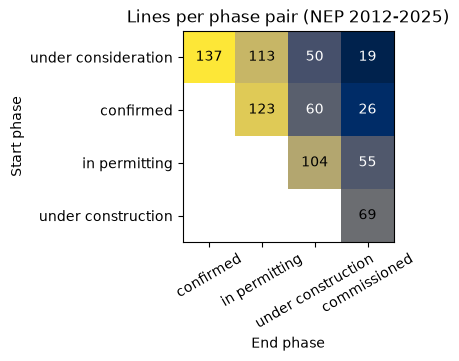

In [4]:
top = units[units.status.isin(OPEN)].status.map(LADDER.index).groupby(units.line_id).max()
done = lines.line_id[(lines.outcome == "commissioned") & (lines.kind != "substation")]
top = top.reindex(top.index.union(done))
top[done] = len(OPEN)
has = {s: set(units.line_id[units.status == s]) for s in OPEN}
reach = {s: set(top.index[top >= LADDER.index(s)]) for s in LADDER[1:]}
n = pd.DataFrame([[len(has[a] & reach[b]) if LADDER.index(a) < LADDER.index(b) else np.nan for b in LADDER[1:]]
                  for a in OPEN], index=OPEN, columns=LADDER[1:])

fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
ax.imshow(n, cmap="cividis")
for (i, j), v in np.ndenumerate(n.to_numpy()):
    if v == v:
        ax.text(j, i, int(v), ha="center", va="center", color="white" if v < n.max().max() / 2 else "black")
labels = [s.replace("_", " ") for s in LADDER]
ax.set(xticks=range(4), xticklabels=labels[1:], yticks=range(4), yticklabels=labels[:-1],
       xlabel="End phase", ylabel="Start phase", title="Lines per phase pair (NEP 2012-2025)")
ax.tick_params(axis="x", labelrotation=30)
plt.show()

**Table 1.** Delay = commissioning year minus the target year of the first report in that phase.
Columns without suffix: commissioned lines with an exact date. `_lb`: also planned lines, with their
latest target (at least 2026) as a stand-in; a lower bound. No substations.

In [5]:
def stats(d: pd.Series) -> pd.Series:
    """n, shares delayed, unchanged, earlier (%), mean delay, mean delay of delayed lines."""
    d = d.dropna()
    pct = lambda m: round(100 * m.sum() / len(d)) if len(d) else np.nan  # noqa: E731
    return pd.Series({"n": len(d), "delayed_pct": pct(d > 0), "unchanged_pct": pct(d == 0), "earlier_pct": pct(d < 0),
                      "mean_delay": round(d.mean(), 1), "mean_if_delayed": round(d[d > 0].mean(), 1)})


exact = obs[obs.exact].groupby("status").delay.apply(stats).unstack()
lb = obs.dropna(subset=["delay_lb"]).groupby("status").delay_lb.apply(stats).unstack()
table1 = exact.join(lb.add_suffix("_lb")).reindex(OPEN)
table1

,n,delayed_pct,unchanged_pct,earlier_pct,mean_delay,mean_if_delayed,n_lb,delayed_pct_lb,unchanged_pct_lb,earlier_pct_lb,mean_delay_lb,mean_if_delayed_lb
status,,,,,,,,,,,,
under_consideration,17.0,71.0,0.0,29.0,2.4,4.2,205.0,59.0,30.0,11.0,3.5,6.6
confirmed,26.0,85.0,4.0,12.0,2.7,3.7,133.0,70.0,10.0,20.0,3.4,5.8
in_permitting,54.0,80.0,13.0,7.0,2.6,3.4,137.0,73.0,18.0,9.0,3.3,4.7
under_construction,55.0,53.0,40.0,7.0,1.2,2.4,67.0,57.0,37.0,6.0,1.8,3.3


**Table 2.** P(cancel) = cancelled / (cancelled + advanced), in %. Cumulative = share of lines starting
under consideration that are cancelled before leaving this phase. Lines only, no substations; replaced
and unknown outcomes left out. Censored = still planned in that phase at the latest report.

In [6]:
def life_table(lines: pd.DataFrame, min_km: float) -> pd.DataFrame:
    """Per phase: cancelled there, advanced to a later phase, or censored (still there)."""
    keep = lines[(lines.kind == "line") & (lines.purpose != "wind_connection") & (lines.length_km > min_km)
                & lines.outcome.isin(["commissioned", "cancelled", "planned"])].set_index("line_id")
    seen = panel[panel.status.isin(OPEN) & panel.line_id.isin(keep.index)][["line_id", "status"]]
    seen = seen.drop_duplicates()
    rank = seen.status.map(LADDER.index)
    top = rank.groupby(seen.line_id).max().reindex(seen.line_id).to_numpy()
    res = keep.outcome.reindex(seen.line_id).to_numpy()
    advanced = (top > rank.to_numpy()) | (res == "commissioned")
    result = np.where(advanced, "advanced", np.where(res == "cancelled", "cancelled", "censored"))
    t = pd.crosstab(seen.status, result)
    t = t.reindex(index=OPEN, columns=["cancelled", "advanced", "censored"], fill_value=0)
    t["n"] = t.sum(axis=1)
    q = t.cancelled / (t.cancelled + t.advanced)
    t["p_cancel"] = (100 * q).round()
    t["cum_cancel"] = (100 * (1 - (1 - q.fillna(0)).cumprod())).round()
    return t


table2 = life_table(lines, MIN_KM)
table2

col_0,cancelled,advanced,censored,n,p_cancel,cum_cancel
status,,,,,,
under_consideration,94,124,139,357,43.0,43.0
confirmed,5,115,18,138,4.0,45.0
in_permitting,5,99,65,169,5.0,48.0
under_construction,0,67,53,120,0.0,48.0


**Figure 1.** Delay distribution per phase reached. Bars: commissioned lines; outline: with planned
lines (lower bound). Commissioned lines cluster at 0-4 years; planned lines add a long tail.

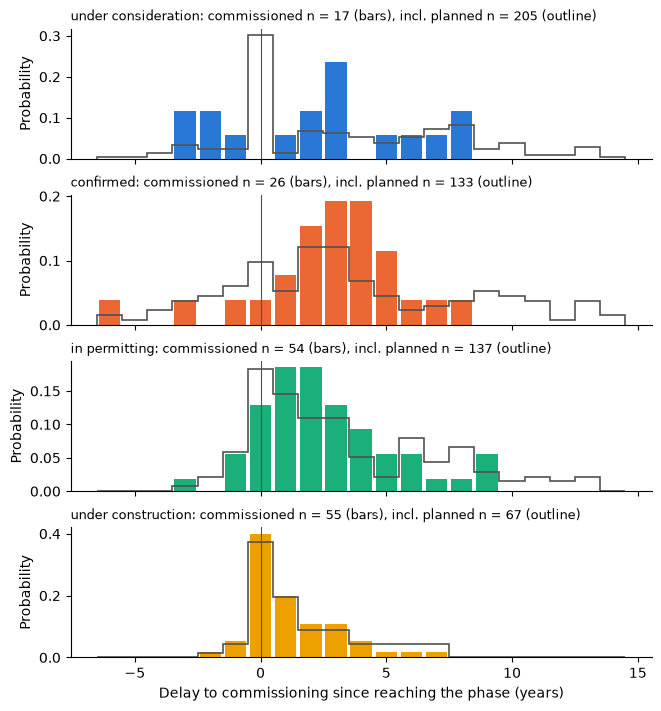

In [7]:
fig, axs = plt.subplots(len(OPEN), 1, figsize=(6.5, 7), sharex=True, layout="constrained")
bins = np.arange(-6, 16) - 0.5
for ax, s in zip(axs, OPEN):
    d = obs[(obs.status == s) & obs.exact].delay.dropna()
    d_lb = obs[obs.status == s].delay_lb.dropna()
    ax.hist(d, bins=bins, weights=np.full(len(d), 1 / max(len(d), 1)), color=COLOURS[s], rwidth=0.85)
    ax.hist(d_lb, bins=bins, weights=np.full(len(d_lb), 1 / max(len(d_lb), 1)), histtype="step",
            color="#52514e", lw=1.2)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_title(f"{s.replace('_', ' ')}: commissioned n = {len(d)} (bars), incl. planned n = {len(d_lb)} (outline)",
                 fontsize=9, loc="left")
    ax.set_ylabel("Probability")
    ax.spines[["top", "right"]].set_visible(False)
axs[-1].set_xlabel("Delay to commissioning since reaching the phase (years)")
plt.show()

**Figure 2.** Time between phases. Reports are 1-2 years apart, so values are upper bounds of the true
phase length; only lines that did move on are counted (no censoring).

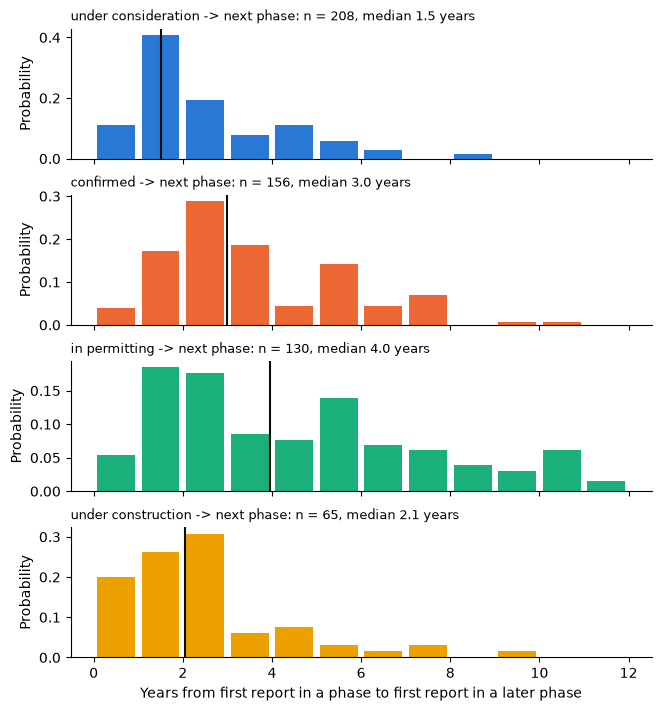

In [8]:
fig, axs = plt.subplots(len(OPEN), 1, figsize=(6.5, 7), sharex=True, layout="constrained")
bins = np.arange(0, 13, 1.0)
for ax, s in zip(axs, OPEN):
    y = durations[durations.status == s].years
    ax.hist(y, bins=bins, weights=np.full(len(y), 1 / max(len(y), 1)), color=COLOURS[s], rwidth=0.85)
    ax.axvline(y.median(), color="#0b0b0b", lw=1.5)
    ax.set_title(f"{s.replace('_', ' ')} -> next phase: n = {len(y)}, median {y.median():.1f} years",
                 fontsize=9, loc="left")
    ax.set_ylabel("Probability")
    ax.spines[["top", "right"]].set_visible(False)
axs[-1].set_xlabel("Years from first report in a phase to first report in a later phase")
plt.show()

Check: the recomputed tables match the nep_panel reports (copies in the data folder, default settings).

In [9]:
ref1 = pd.read_csv(DATA / "delay_table.csv", index_col=0)
ref2 = pd.read_csv(DATA / "cancellation.csv", index_col=[0, 1])
ok1 = (table1.fillna(-1).to_numpy() == ref1.fillna(-1).to_numpy()).all()
ok2 = all((life_table(lines, k).to_numpy() == ref2.loc[f"lines > {k} km"].to_numpy()).all() for k in (0, 20))
assert ok1 and ok2, "recomputed tables differ from nep_panel/reports"
{"table 1 matches report": bool(ok1), "table 2 matches report": bool(ok2)}

{'table 1 matches report': True, 'table 2 matches report': True}

## Inputs for the probability builder

The builder draws, for every NEP 2023 project that is **confirmed, in permitting or under construction**, a delay
on top of its target year, and drops it with a cancellation probability. It needs three inputs:

1. **Delay distribution per status**, P(D <= t | status), with D = commissioning year minus the target year of a
   report in which the line had that status.
2. **Cancellation probability** before commissioning, per status.
3. **Correlation** of delays between projects.

Lines under consideration are left out: 43 % of them are cancelled in that phase (Table 2), and the builder
does not include such projects.

In [10]:
BUILDER = ["confirmed", "in_permitting", "under_construction"]
MIN_LEAD = 3  # years from report to target; NEP 2023 projects in the builder have targets 2026+, so lead >= 3
N_BOOT = 200
rng = np.random.default_rng(0)
OLD = {0: 36, 1: 13, 2: 15, 3: 8, 4: 6, 5: 6, 6: 6, 7: 1, 8: 2, 9: 4, 10: 2, 11: 2, 12: 2, 13: 1, 14: 1}
old = pd.Series(OLD, dtype=float).div(sum(OLD.values()))  # pooled BNetzA histograms of the old builder

### Delay per status: every report counts, censoring kept

The builder adds a delay to the target of one report (NEP 2023). The matching observation is one report:
a line in status *s* with target year *T*. Every report of a line in *s* counts, weighted 1/*k* (*k* = its reports
in *s*), so long-lived lines do not dominate. Only reports with a lead (target minus report year) of at least
`MIN_LEAD` years count, like the builder's projects (Table 4 shows why).

D is known as an interval:

| Outcome | D |
|---|---|
| commissioned, exact date | one year |
| commissioned, "realised since the last report" | two possible years |
| commissioned, upper bound only | at most hi - T |
| still planned in NEP 2025 (March 2026) | at least 2026 - T (right-censored) |

Turnbull's estimator (the Kaplan-Meier generalisation for interval-censored data; Turnbull 1976) uses all of
them. Mass beyond the largest observed bound is kept as D = inf: such lines are still open later than any
commissioned one. Cancelled, replaced and unknown lines are left out here; cancellation is a separate input.

In [11]:
def delay_intervals(panel: pd.DataFrame, lines: pd.DataFrame) -> pd.DataFrame:
    """One row per line and report in a builder status, with the delay interval [lo, hi] in years."""
    keep = (lines.kind == "line") & (lines.purpose != "wind_connection") & lines.outcome.isin(["commissioned", "planned"])
    ln = lines[keep].set_index("line_id")
    done = ln.outcome == "commissioned"
    exact = ln.precision.isin(EXACT)
    lo = ln.actual_year.where(exact, ln.actual_lo.where(ln.precision != "upper_bound", -np.inf)).where(done, CENSOR_YEAR)
    hi = ln.actual_year.where(exact, ln.actual_hi).where(done, np.inf)
    ok = ln.index[lo.notna() & hi.notna()]
    d = panel[panel.line_id.isin(ok) & panel.status.isin(BUILDER)].dropna(subset=["target_hi"])
    year = pd.to_datetime(d.ref_date).dt.year
    return d.assign(year=year, lead=d.target_hi - year, lo=d.line_id.map(lo) - d.target_hi,
                    hi=d.line_id.map(hi) - d.target_hi)


def turnbull(lo: np.ndarray, hi: np.ndarray, w: np.ndarray, tol: float = 1e-9) -> pd.Series:
    """Turnbull NPMLE of a discrete distribution from weighted interval-censored data [lo, hi].

    Mass sits only on finite upper bounds (observed end years) and on inf: an open line later than every
    observed end year has its whole weight at inf, not at its lower bound.
    """
    k = np.r_[np.unique(hi[np.isfinite(hi)]), np.inf]
    a = (k >= lo[:, None]) & (k <= hi[:, None])
    p = np.full(k.size, 1 / k.size)
    for _ in range(100_000):
        q = a * p
        new = w @ (q / q.sum(axis=1, keepdims=True)) / w.sum()
        if np.abs(new - p).max() < tol:
            return pd.Series(new, k)
        p = new
    raise RuntimeError("Turnbull did not converge")


def pmf(d: pd.DataFrame) -> pd.Series:
    """Delay distribution of one sample, each line weighted 1."""
    w = 1 / d.groupby("line_id").line_id.transform("size")
    return turnbull(d.lo.to_numpy(float), d.hi.to_numpy(float), w.to_numpy())


def cdf(p: pd.Series, grid: np.ndarray) -> np.ndarray:
    """P(D <= t) on a grid."""
    return np.array([p[p.index <= t].sum() for t in grid])


# checks: without censoring the estimate is the empirical distribution; censored mass moves to later events;
# an open line beyond every observed end year goes to inf
x = np.array([0.0, 1, 1, 3])
assert np.allclose(turnbull(x, x, np.ones(4)), [0.25, 0.5, 0.25, 0])
assert np.allclose(turnbull(np.array([1.0, 2, 3]), np.array([1, np.inf, 3]), np.ones(3)), [1 / 3, 2 / 3, 0], atol=1e-6)
assert np.allclose(turnbull(np.array([1.0, 4]), np.array([1, np.inf]), np.ones(2)), [0.5, 0.5])

d_all = delay_intervals(panel, lines)
sel = d_all[d_all.lead >= MIN_LEAD]
pmfs = {s: pmf(sel[sel.status == s]) for s in BUILDER}
naive = {s: pmf(sel[(sel.status == s) & np.isfinite(sel.hi)]) for s in BUILDER}  # commissioned lines only


**Table 3.** P(D <= t) per status (lead >= 3 years). "beyond" = mass later than any observed bound
(treated as never by 2035). Lines = lines behind the estimate; commissioned = those with a known outcome. Last
row: the pooled BNetzA histograms of the old builder.

In [12]:
TS = [0, 1, 2, 3, 5, 9]


def row(p: pd.Series) -> dict:
    """P(D <= t) for TS, the median and the mass beyond all bounds."""
    c = p.cumsum()
    return {f"P(D<={t})": round(cdf(p, [t])[0], 2) for t in TS} | {
        "median": c.index[(c >= 0.5).to_numpy().argmax()], "beyond": round(p.iloc[-1], 2)}


table3 = pd.DataFrame({s: {"lines": sel[sel.status == s].line_id.nunique(),
                           "commissioned": sel[(sel.status == s) & np.isfinite(sel.hi)].line_id.nunique(), **row(pmfs[s])}
                       for s in BUILDER}).T
table3.loc["old builder (BNetzA)"] = {"lines": 105, "commissioned": 34, **row(pd.concat([old, pd.Series({np.inf: 0.0})]))}
table3

,lines,commissioned,P(D<=0),P(D<=1),P(D<=2),P(D<=3),P(D<=5),P(D<=9),median,beyond
confirmed,131.0,24.0,0.10,0.15,0.23,0.33,0.59,0.67,5.0,0.33
in_permitting,145.0,37.0,0.17,0.31,0.42,0.53,0.63,0.89,3.0,0.11
under_construction,36.0,13.0,0.39,0.53,0.61,0.61,0.72,1.00,1.0,0.00
old builder (BNetzA),105.0,34.0,0.34,0.47,0.61,0.69,0.80,0.92,2.0,0.00


**Figure 3.** Probability that a line is commissioned at most *t* years after the target year of a report
in that status. Colour: censoring-aware estimate with 90 % bootstrap band (lines resampled). Dashed: commissioned
lines only, which drops lines still running late. Grey: the old builder's pooled BNetzA sample.

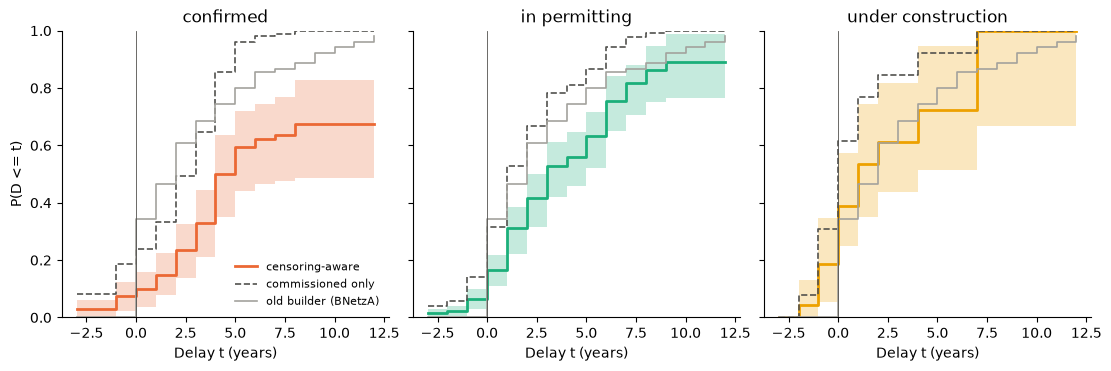

In [13]:
def resample(d: pd.DataFrame) -> pd.DataFrame:
    """Bootstrap sample: lines drawn with replacement, each copy a new line."""
    parts = dict(tuple(d.groupby("line_id")))
    ids = np.array(list(parts))
    return pd.concat([parts[i].assign(line_id=j) for j, i in enumerate(rng.choice(ids, ids.size))])


def band(d: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """5 and 95 % bootstrap quantiles of P(D <= t), resampling lines."""
    reps = [cdf(pmf(resample(d)), grid) for _ in range(N_BOOT)]
    return np.percentile(reps, [5, 95], axis=0)


grid = np.arange(-3, 13)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, s in zip(axs, BUILDER):
    lo_b, hi_b = band(sel[sel.status == s], grid)
    ax.fill_between(grid, lo_b, hi_b, step="post", color=COLOURS[s], alpha=0.25, lw=0)
    ax.step(grid, cdf(pmfs[s], grid), where="post", color=COLOURS[s], lw=2, label="censoring-aware")
    ax.step(grid, cdf(naive[s], grid), where="post", color="#52514e", lw=1.2, ls="--", label="commissioned only")
    ax.step(grid, cdf(old, grid), where="post", color="#a3a29d", lw=1.2, label="old builder (BNetzA)")
    ax.axvline(0, color="#52514e", lw=0.6)
    ax.set(title=s.replace("_", " "), xlabel="Delay t (years)", ylim=(0, 1))
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("P(D <= t)")
axs[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.show()

**Table 4.** Does the delay depend on lead time, report period or technology? Same estimator; lead uses
all reports, period and technology only lead >= 3. Small cells (< 10 commissioned lines) are noisy: the estimator
then puts much mass on few points.

In [14]:
def split(d: pd.DataFrame, key: pd.Series, name: str) -> pd.DataFrame:
    """Table 3 columns per status and group of ``key``."""
    rows = [{"status": s, "split": name, "group": str(g), "lines": x.line_id.nunique(),
             "commissioned": x[np.isfinite(x.hi)].line_id.nunique(), **row(pmf(x))}
            for (s, g), x in d.groupby(["status", key], observed=True)]
    return pd.DataFrame(rows)


lead_class = pd.cut(d_all.lead, [-np.inf, 2, 4, 7, np.inf], labels=["<=2", "3-4", "5-7", ">=8"])
period = pd.cut(sel.year, [2011, 2016, 2020, 2026], labels=["2012-2016", "2017-2020", "2021-2026"])
table4 = pd.concat([split(d_all, lead_class, "lead (years)"), split(sel, period, "report"), split(sel, sel.tech, "tech")])
table4.set_index(["status", "split", "group"]).drop(columns=["P(D<=1)", "P(D<=3)"])

lines  commissioned  P(D<=0)  \
status             split        group                                     
confirmed          lead (years) <=2            5             5     0.20   
                                3-4           28            13     0.09   
                                5-7           70            17     0.09   
                                >=8           93             5     0.00   
in_permitting      lead (years) <=2           58            38     0.21   
                                3-4           99            33     0.13   
                                5-7          100            20     0.15   
                                >=8           43             3     0.19   
under_construction lead (years) <=2          104            66     0.58   
                                3-4           28            13     0.41   
                                5-7            8             1     0.00   
                                >=8            2             0     0.00   
confirmed          report       2012-2016     50            22     0.06   
                                2017-2020     82            10     0.14   
                                2021-2026     77             0     0.00   
in_permitting      report       2012-2016     38            20     0.00   
                                2017-2020     64            26     0.16   
                                2021-2026    117            11     0.35   
under_construction report       2012-2016      4             3     0.00   
                                2017-2020     12             7     0.28   
                                2021-2026     26             6     0.63   
confirmed          tech         AC           122            22     0.11   
                                DC            10             3     0.00   
in_permitting      tech         AC           132            37     0.17   
                                DC            14             0     0.00   
under_construction tech         AC            35            12     0.41   
                                DC             1             1     0.00   

                                           P(D<=2)  P(D<=5)  P(D<=9)  median  \
status             split        group                                          
confirmed          lead (years) <=2           0.60     1.00     1.00     1.0   
                                3-4           0.21     0.62     0.67     5.0   
                                5-7           0.20     0.46     0.85     6.0   
                                >=8           0.22     1.00     1.00     4.0   
in_permitting      lead (years) <=2           0.55     0.81     1.00     2.0   
                                3-4           0.36     0.58     0.87     4.0   
                                5-7           0.38     0.66     1.00     4.0   
                                >=8           0.19     1.00     1.00     5.0   
under_construction lead (years) <=2           0.89     0.98     0.99     0.0   
                                3-4           0.62     0.73     1.00     1.0   
                                5-7           1.00     1.00     1.00     1.0   
                                >=8           0.00     0.00     0.00     inf   
confirmed          report       2012-2016     0.20     0.52     0.62     5.0   
                                2017-2020     0.28     0.68     0.68     5.0   
                                2021-2026     0.00     0.00     0.00     inf   
in_permitting      report       2012-2016     0.14     0.36     0.77     6.0   
                                2017-2020     0.43     0.64     0.64     3.0   
                                2021-2026     0.35     0.35     0.35     inf   
under_construction report       2012-2016     0.25     0.50     1.00     4.0   
                                2017-2020     0.63     0.63     0.63     2.0   
                                2021-2026     0.63     0.63     0.63     0.0   
confirmed          tech    

Reading Table 4:

- **Lead time matters for construction.** Lines under construction with a target at most 2 years ahead are
  mostly on time; with 3+ years ahead they slip like lines in permitting. Hence `MIN_LEAD = 3`: all stochastic
  builder projects have NEP 2023 targets of 2026 or later.
- **Report period:** lines in permitting in 2012-2016 reports slipped more than those of 2017-2020 (P(D <= 2)
  0.14 vs 0.43). Reports since 2021 have few commissioned lines yet; their estimates rest on little data. The pooled
  estimate assumes a stable delay process; if delays have shrunk, it is pessimistic.
- **Technology:** DC lines are few; their estimates are too noisy for a separate input.

### Cancellation after reaching a status

From the life table (Table 2): P(cancel | in phase) = cancelled / (cancelled + advanced). A project in status *s*
must still pass *s* and every later phase, so P(cancelled before commissioning | s) = 1 - product of
(1 - P(cancel | phase)) over *s* and the later phases.

**Table 5.** Cancellation before commissioning, per status, all lines and per technology.

In [15]:
def remaining(t: pd.DataFrame) -> pd.Series:
    """P(cancelled before commissioning) from each phase on."""
    q = (t.cancelled / (t.cancelled + t.advanced)).fillna(0)
    return 1 - (1 - q)[::-1].cumprod()[::-1]


table5 = pd.DataFrame({name: remaining(life_table(lines[mask], 0)) for name, mask in
                       {"all": lines.tech.notna(), "AC": lines.tech == "AC", "DC": lines.tech == "DC"}.items()})
counts = life_table(lines, 0)[["cancelled", "advanced"]]
table5 = table5.join(counts).loc[BUILDER]
table5.round(3)

,all,AC,DC,cancelled,advanced
status,,,,,
confirmed,0.088,0.084,0.143,5,115
in_permitting,0.048,0.041,0.143,5,99
under_construction,0.000,0.000,0.000,0,67


Under construction, 0 of the lines that left the phase were cancelled; with that sample, a true rate of a few
percent cannot be excluded (rule of three: about 3/n). The old builder used European TYNDP rates (0.13 under
construction, 0.32 AC, 0.14 DC); German NEP lines are cancelled far less often once they are confirmed.

### Correlation of delays

The builder links projects with a Gaussian copula: per Monte Carlo draw, a shared normal *Z* moves all projects,
z_i = sqrt(rho) Z + sqrt(1 - rho) e_i, and each delay is the quantile of its status distribution at Phi(z_i).
rho is then the correlation of two projects' delays on the normal-score scale (one-factor model; Vasicek 2002).

Final delays overlap in time and are often censored, so rho is estimated from **target slips** instead: the change
of a line's target year between consecutive NEP reports, per year between them. Lines in the same period share
common shocks (law changes, supply chains, reporting practice). The intra-class correlation (ICC) of the normal
scores of slips within a period estimates rho. Within the same NEP project and period, the same statistic gives
the correlation of measures of one project. If a delay is the sum of its period slips, and common and individual
parts add up independently over periods, the ICC of slips carries over to total delays.

**Table 6.** Target slip per period (lines in a builder status, target not yet passed).

In [16]:
def slips(panel: pd.DataFrame, ids: pd.Series) -> pd.DataFrame:
    """Target change between consecutive NEP reports per line in a builder status, in years per year."""
    p = panel[panel.line_id.isin(ids) & panel.wave.str.startswith("NEP")].sort_values(["line_id", "ref_date"])
    p = p.assign(t=pd.to_datetime(p.ref_date))
    nxt = p.groupby("line_id")[["target_hi", "t", "wave"]].shift(-1)
    s = p.assign(slip=nxt.target_hi - p.target_hi, years=(nxt.t - p.t).dt.days / 365.25,
                 period=p.wave.str[3:] + "-" + nxt.wave.str[3:].fillna(""))
    s = s[s.status.isin(BUILDER) & s.slip.notna() & (s.target_hi >= s.t.dt.year)]
    s = s[s.groupby("period").period.transform("size") >= 10]
    return s.assign(rate=s.slip / s.years)


def nscore(x: pd.Series) -> pd.Series:
    """Normal scores (mid-ranks)."""
    return pd.Series(norm.ppf(rankdata(x) / (len(x) + 1)), x.index)


def icc(z: pd.Series, g: pd.Series) -> float:
    """Pairwise intra-class correlation: mean product of standardised values over pairs within a group."""
    z = (z - z.mean()) / z.std()
    a = z.groupby(g).agg(["sum", "size"])
    return ((a["sum"] ** 2).sum() - (z**2).sum()) / (a["size"] * (a["size"] - 1)).sum()


def groups(s: pd.DataFrame, level: str) -> pd.Series:
    """Grouping for the ICC: period, or project (or another column) within period."""
    return s.period if level == "period" else s.period + "|" + s[level].astype(str)


def boot_icc(s: pd.DataFrame, level: str) -> np.ndarray:
    """5 and 95 % bootstrap quantiles, resampling periods."""
    per = s.period.unique()
    reps = []
    for _ in range(N_BOOT):
        b = pd.concat([s[s.period == q].assign(period=f"{q}#{i}") for i, q in enumerate(rng.choice(per, per.size))])
        reps.append(icc(nscore(b.rate), groups(b, level)))
    return np.percentile(reps, [5, 95])


sl = slips(panel, lines.line_id[(lines.kind == "line") & (lines.purpose != "wind_connection")])
table6 = sl.groupby("period").agg(lines=("rate", "size"), mean_rate=("rate", "mean"),
                                  unchanged_pct=("slip", lambda x: 100 * (x == 0).mean()))
table6.round(2)

,lines,mean_rate,unchanged_pct
period,,,
2012-2013,17,0.96,41.18
2013-2014,54,0.88,46.30
2014-2015,90,0.78,55.56
2015-2017,101,0.93,34.65
2017-2019,92,0.57,34.78
2019-2021,97,1.31,11.34
2021-2023,125,0.05,50.40
2023-2025,133,0.33,48.12


**Figure 4.** Target slip per period: each dot one line (jittered), black bar the mean. Means differ
between periods by more than chance; that shared part is the correlation.

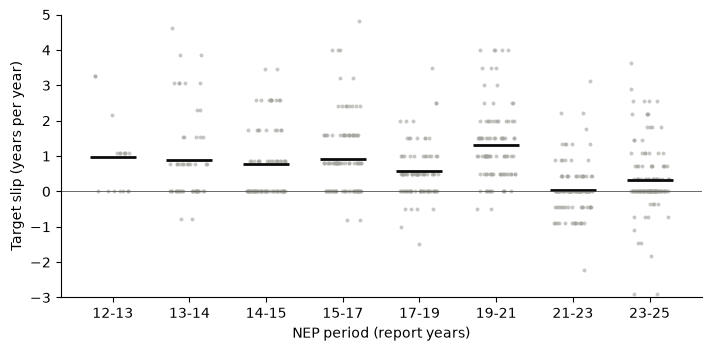

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
for i, (q, x) in enumerate(sl.groupby("period")):
    ax.scatter(i + rng.uniform(-0.25, 0.25, len(x)), x.rate, s=8, color="#a3a29d", alpha=0.6, lw=0)
    ax.hlines(x.rate.mean(), i - 0.3, i + 0.3, color="#0b0b0b", lw=2)
ax.axhline(0, color="#52514e", lw=0.6)
ax.set(xticks=range(sl.period.nunique()), xticklabels=[q[2:4] + "-" + q[-2:] for q in sorted(sl.period.unique())], xlabel="NEP period (report years)",
       ylabel="Target slip (years per year)", ylim=(-3, 5))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Table 7.** Correlation estimates with 90 % bootstrap intervals (periods resampled). Lag-1: correlation
of a line's slip with its own next slip.

In [18]:
z = nscore(sl.rate)
table7 = pd.DataFrame({level: {"rho": icc(z, groups(sl, level)), **dict(zip(["lo", "hi"], boot_icc(sl, level))),
                               "groups": groups(sl, level).nunique()} for level in ["period", "project"]}).T
s2 = sl.assign(z=z).sort_values(["line_id", "t"])
lag1 = s2.z.corr(s2.groupby("line_id").z.shift(-1))
print(f"lag-1 autocorrelation of slips within a line: {lag1:.2f}")
display(table7.round(3))


def pair_corr(z: pd.Series, a: pd.Series, b: pd.Series, g: pd.Series) -> float:
    """Mean product of standardised values over pairs (one from a, one from b, a != b) within a group."""
    z = (z - z.mean()) / z.std()
    sa, sb = z[a].groupby(g[a]).sum(), z[b].groupby(g[b]).sum()
    na, nb_ = a.groupby(g).sum(), b.groupby(g).sum()
    both = z[a & b] ** 2
    return ((sa * sb).sum() - both.groupby(g[a & b]).sum().sum()) / ((na * nb_).sum() - (a & b).sum())


# robustness: period correlation per pair of statuses (pooled rho above is used by the builder)
by_status = pd.DataFrame({a: {b: pair_corr(z, sl.status == a, sl.status == b, sl.period) for b in BUILDER}
                          for a in BUILDER})
print(f"slips per status: {sl.status.value_counts().to_dict()}")
by_status.round(3)

lag-1 autocorrelation of slips within a line: -0.15


,rho,lo,hi,groups
period,0.174,0.024,0.267,8.0
project,0.535,0.271,0.821,380.0


slips per status: {'in_permitting': 348, 'confirmed': 293, 'under_construction': 68}


,confirmed,in_permitting,under_construction
confirmed,0.201,0.179,0.004
in_permitting,0.179,0.205,0.149
under_construction,0.004,0.149,0.352


Reading Table 7:

- **Period correlation rho ~ 0.17** (90 % interval roughly 0.03-0.26): about a sixth of the slip variance is shared
  by all lines in a period. The old builder used 0.03, at the bottom of that range. With only 8 periods, the interval is wide.
- **Same NEP project: ~ 0.54.** Measures of one project (`NEP_P302_M511`, `NEP_P302_M512` -> `P302`) move
  together much more. **Not exported:** the builder's sensitivity shows that an extra project factor changes the
  scenario weights only by Monte Carlo noise. Only 0.7 % of the capacity-weighted project pairs share a NEP project,
  while the period factor links all pairs. The builder therefore uses the period rho alone.
- **Lag-1 is slightly negative:** a line's slips do not persist, so the slip ICC is not inflated by persistent
  individual delays. Part of the period effect may be reporting practice (e.g. the NEP 2019-2021 jump, then a
  pause), not physical delay. The estimate is an upper reference for "true" common shocks.

**Possible extension (not done): BNetzA quarterly monitoring.** The period rho rests on 8 NEP periods, so its
interval is wide. The Bundesnetzagentur publishes a monitoring report every quarter since 2013
([netzausbau.de/Daten/monitoring](https://www.netzausbau.de/Daten/monitoring/de.html), PDF archives per year).
Per EnLAG and BBPlG project it gives the operators' expected commissioning year ("Gesamtinbetriebnahme"),
built sections, and a list of changes since the last quarter with reasons. Target slips per year (Q4 to Q4) would
give about 12 periods instead of 8. Limits:

- Expected years are whole years and change rarely (2017: 0-3 of about 65 projects per quarter), so quarterly
  slips are mostly 0; only yearly periods are usable. Common shocks may last longer than a year, so the gain in
  independent periods may be smaller than 12 vs 8.
- 2013-2015 cover only the 24 EnLAG projects; BBPlG projects follow from about 2016.
- Projects are BBPlG/EnLAG projects, larger than NEP measures; feeding the panel needs a BBPlG-to-NEP mapping.
- The years are operator expectations, like the NEP targets, so reporting practice stays in the estimate.
- PDF only, with layout changes over the years: about 54 reports to parse.

The change lists with reasons are the most useful part: they show whether the period effect comes from a few policy
events (e.g. the underground-cable priority from 2015), which would better be modelled as explicit scenarios than as
a random common shock.


### Comparison: TYNDP panel

`data/pypsa-de/grid_delay/tyndp_panel/panel_long.csv`: one row per TYNDP investment and report (2010-2026, biennial
from 2016), with status and expected commissioning year. Same slip statistic as Table 7: change of the expected year
between consecutive reports, per year, for lines (no substations, no wind connections) in TYNDP status 2-4
(2 = planned, not yet permitting, taken as confirmed). Project = TYNDP project; Germany = lines with `DE_scope`.
`country` groups single-country lines by country within a period; `Germany internal` = German-only lines.

**Table 8.** Correlation estimates per sample, 90 % bootstrap intervals (periods resampled).


In [ ]:
TYNDP = DATA.parent / "tyndp_panel" / "panel_long.csv"
TYNDP_STATUS = {2: "confirmed", 3: "in_permitting", 4: "under_construction"}
TYNDP_REPORTS = [2010, 2012, 2013, 2014, 2015, 2016, 2018, 2020, 2022, 2024, 2026]


def tyndp_slips(p: pd.DataFrame) -> pd.DataFrame:
    """Change of expected commissioning year between consecutive TYNDP reports per line, in years per year."""
    p = p[(p.Present == 1) & p.Comm_Year.notna() & (p.Inv_Element_Category == "Cable/Line") & ~p.Wind_Connection]
    p = p.sort_values(["Inv_index", "Year"]).assign(rank=lambda d: d.Year.map(TYNDP_REPORTS.index))
    nxt = p.groupby("Inv_index")[["Comm_Year", "Year", "rank"]].shift(-1)
    s = p.assign(slip=nxt.Comm_Year - p.Comm_Year, years=nxt.Year - p.Year, status=p.Status.map(TYNDP_STATUS),
                 period=p.Year.astype(str) + "-" + nxt.Year.astype("Int64").astype(str), project=p.Project_Name,
                 country=p.Project_Country_ISO3, line_id=p.Inv_index)
    s = s[s.status.notna() & s.slip.notna() & (nxt["rank"] - p["rank"] == 1) & (s.Comm_Year >= s.Year)]
    s = s[s.groupby("period").period.transform("size") >= 10]
    return s.assign(rate=s.slip / s.years)


ts = tyndp_slips(pd.read_csv(TYNDP))
one = ts[~ts.country.str.contains(";")]
de = ts[ts.DE_scope.notna()]
runs = [("NEP", sl, "period"), ("NEP", sl, "project"),
        ("TYNDP Europe", ts, "period"), ("TYNDP Europe", ts, "project"),
        ("TYNDP Europe", one, "country"), ("TYNDP Europe without Germany", one[one.country != "DEU"], "country"),
        ("TYNDP Germany", de, "period"), ("TYNDP Germany", de, "project"),
        ("TYNDP Germany internal", de[de.DE_scope == "Internal"], "period")]
table8 = pd.DataFrame([{"sample": name, "level": level, "rho": icc(nscore(s.rate), groups(s, level)),
                        **dict(zip(["lo", "hi"], boot_icc(s, level))), "groups": groups(s, level).nunique(),
                        "slips": len(s), "lines": s.line_id.nunique()} for name, s, level in runs]).set_index(["sample", "level"])
display(ts.groupby("period").agg(lines=("rate", "size"), germany=("DE_scope", "count"), mean_rate=("rate", "mean")).round(2))
table8.round(3)


Reading Table 8 (TYNDP: 1225 slips of 373 lines in 201 projects; Germany: 227 slips of 65 lines, 43 projects,
of which internal 133 slips of 39 lines, 19 projects):

- **No European shock** (period rho ~ 0.005): bad years differ by country and cancel out when pooled.
- **Within country and period ~ 0.14**, but 59 % of its pairs are German, so it largely repeats Germany. Without
  Germany ~ 0.16, carried mainly by Italy, Czechia, Portugal and Switzerland. Per country (>= 30 slips) rho scatters
  from -0.19 (Austria) to 0.25 (Switzerland); Belgium, Poland, Austria and the UK are negative. In small countries
  (e.g. Czechia: 9 lines, 3 projects) the country value partly measures the project correlation. Permanent
  country differences in mean slip explain < 1 % of the variance.
- **Germany: 0.13-0.14 for internal lines, ~ 0.08 with cross-border lines** (these also carry the neighbour's
  shocks). Like the NEP, it rests on about 8 usable periods (2010-2013 hold 1-3 German slips), so it is a cross-check
  of the NEP's 0.17, not a more precise estimate.
- **Project level:** 0.36 (Europe) and 0.26 (Germany), lower than the NEP's 0.54 but clearly above the period level.
- The builder keeps the NEP period rho; the TYNDP points to slightly lower values (0.13-0.14), within its interval.


### Export for the builder

| File | Content |
|---|---|
| `delay_pmf.csv` | status, delay (years; `inf` = beyond all observed), probability (Table 3) |
| `delay_pmf_boot.csv` | status, rep, delay, probability: `N_BOOT` bootstrap estimates of the same (lines resampled, as in Figure 3) |
| `cancel_rate.csv` | status, p_cancel (all lines), cancelled and advanced counts (Table 5) |
| `delay_correlation.csv` | level (period only), rho, lo, hi, groups (Table 7) |

In [19]:
out = pd.concat(pmfs, names=["status", "delay"]).rename("probability")
out.to_csv(DATA / "delay_pmf.csv")
boot = {s: pd.concat({b: pmf(resample(sel[sel.status == s])) for b in range(N_BOOT)}) for s in BUILDER}
pd.concat(boot, names=["status", "rep", "delay"]).rename("probability").to_csv(DATA / "delay_pmf_boot.csv")
table5[["all", "cancelled", "advanced"]].rename(columns={"all": "p_cancel"}).rename_axis("status").to_csv(
    DATA / "cancel_rate.csv")
table7.loc[["period"]].rename_axis("level").to_csv(DATA / "delay_correlation.csv")
assert np.allclose(out.groupby(level=0).sum(), 1)
sorted(p.name for p in DATA.glob("*.csv"))

['cancel_rate.csv',
 'cancellation.csv',
 'delay_correlation.csv',
 'delay_pmf.csv',
 'delay_table.csv',
 'lines.csv',
 'panel.csv']

### References

- Turnbull, B. W. (1976). The empirical distribution function with arbitrarily grouped, censored and truncated
  data. *JRSS B* 38(3), 290-295.
- Vasicek, O. (2002). The distribution of loan portfolio value. *Risk* 15(12), 160-162.